![image.png](week-11-diagram.svg)

![image.png](distributed-training-curriculum4.svg)

![image.png](distributed-training-objectives.svg)

## 单卡训练的**7+1步训练法**


---

### ✅  Huggingface的Trainer类 大模型训练七步法代码结构 

---
```python
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "/deepseekr1-1.5b"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name).eval()

print("——模型加载成功——")

input_text = "请问如何提升我的面试表现？"
inputs = tokenizer(input_text, return_tensors="pt")

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=True,
        top_k=50,
        top_p=0.95,
        temperature=0.8
    )

output_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
print("——模型回复——")
print(output_text)
```

---
    
#### 1. **准备数据集 `datasets.jsonl**
```python
with open("datasets.jsonl", "w", encoding="utf-8") as f:
    for s in samples:
        json_line = json.dumps(s, ensure_ascii=False)
        f.write(json_line + "\n")
print("prepare data finished")
```

---

#### 2. **加载数据集并切分**
```python
from datasets import load_dataset

dataset = load_dataset(path="json", data_files={"train": "datasets.jsonl"}, split="train")
print("数据总量: ", len(dataset))

train_test_split = dataset.train_test_split(test_size=0.1)
train_dataset = train_test_split["train"]
eval_dataset = train_test_split["test"]

print(f"train dataset len: {len(train_dataset)}")
print(f"test dataset len: {len(eval_dataset)}")
```

---

#### 3. **Tokenizer 处理函数**
```python
def tokenizer_function(many_samples):
    texts = [f"{prompt}\n{completion}" for prompt, completion in zip(many_samples["prompt"], many_samples["completion"])]
    tokens = tokenizer(texts, truncation=True, max_length=512, padding="max_length")
    tokens["labels"] = tokens["input_ids"].copy()
    return tokens

tokenized_train_dataset = train_dataset.map(tokenizer_function, batched=True)
tokenized_eval_dataset = eval_dataset.map(tokenizer_function, batched=True)

print("完成tokenizing")
```

---

#### 4. **加载预训练模型并设置量化（可选）**
```python
from transformers import BitsAndBytesConfig, AutoTokenizer, AutoModelForCausalLM

model_name = "/data/deepseek-sft/deepseekr1-1.5b"
tokenizer = AutoTokenizer.from_pretrained(model_name)
quantization_config = BitsAndBytesConfig(load_in_8bit=True)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto"
)
print("已经完成量化模型的加载")
```

---

#### 5. **LoRA 微调配置**
```python
from peft import get_peft_model, LoraConfig, TaskType

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    task_type=TaskType.CAUSAL_LM
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("lora微调设置完毕")
```

---

#### 6. **训练参数配置**
```python
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./finetuned_models",
    num_train_epochs=10,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=8,
    fp16=True,
    logging_steps=10,
    save_steps=100,
    eval_strategy="steps",
    eval_steps=10,
    learning_rate=3e-5,
    logging_dir="./logs",
    run_name="deepseek-r1-distill-finetune"
)
```

---

#### 7. **开始训练**
```python
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train_dataset,
    eval_dataset=tokenized_eval_dataset,
    tokenizer=tokenizer
)

trainer.train()
```

---

#### 第八步：合并 LoRA 模型权重

适用于使用了 [PEFT (LoRA)](https://github.com/huggingface/peft) 训练的 Causal LM，例如 DeepSeek / LLaMA / GPT 等。

---

##### 代码（基于 transformers + peft）

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

# 模型路径
base_model_path = "your_model_path"
lora_model_path = "./finetuned_lora"
merged_model_path = "./merged_model"

# 加载基础模型
model = AutoModelForCausalLM.from_pretrained(base_model_path)

# 加载 LoRA adapter
model = PeftModel.from_pretrained(model, lora_model_path)

# 合并 adapter 权重到 base model
model = model.merge_and_unload()

# 保存合并后的完整模型
model.save_pretrained(merged_model_path)
tokenizer = AutoTokenizer.from_pretrained(base_model_path)
tokenizer.save_pretrained(merged_model_path)

print(f"✅ LoRA 模型已成功合并并保存至 {merged_model_path}")
```

---

##### ✅ 保存后你可以这样加载：

```python
from transformers import AutoTokenizer, AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained("./merged_model")
tokenizer = AutoTokenizer.from_pretrained("./merged_model")

inputs = tokenizer("你好，给我讲个笑话吧", return_tensors="pt")
outputs = model.generate(**inputs, max_new_tokens=100)
print(tokenizer.decode(outputs[0], skip_special_tokens=True))
```

---

#### 补充说明：

| 步骤                     | 是否必须 | 用途说明                     |
|--------------------------|----------|------------------------------|
| `merge_and_unload()`     | ✅ 必须  | 将 LoRA adapter 权重合并进 base 模型 |
| `save_pretrained()`      | ✅ 必须  | 存为 HuggingFace 可部署格式 |
| 原始 base 模型           | ✅ 必须  | 合并前你仍需加载它           |
| adapter 模型（LoRA）     | ✅ 必须  | 即你在训练后保存的 LoRA 路径 |



![image.png](distributed-training-slide.svg)

# 前置知识：
1. 梯度更新时的一阶动量、二阶动量
2. 混合精度训练

### ✅ 什么是一阶、二阶动量？

- **一阶动量**：平滑梯度，避免“抖动”，加快方向收敛  
- **二阶动量**：自适应每个维度的学习率，避免更新过大或过小
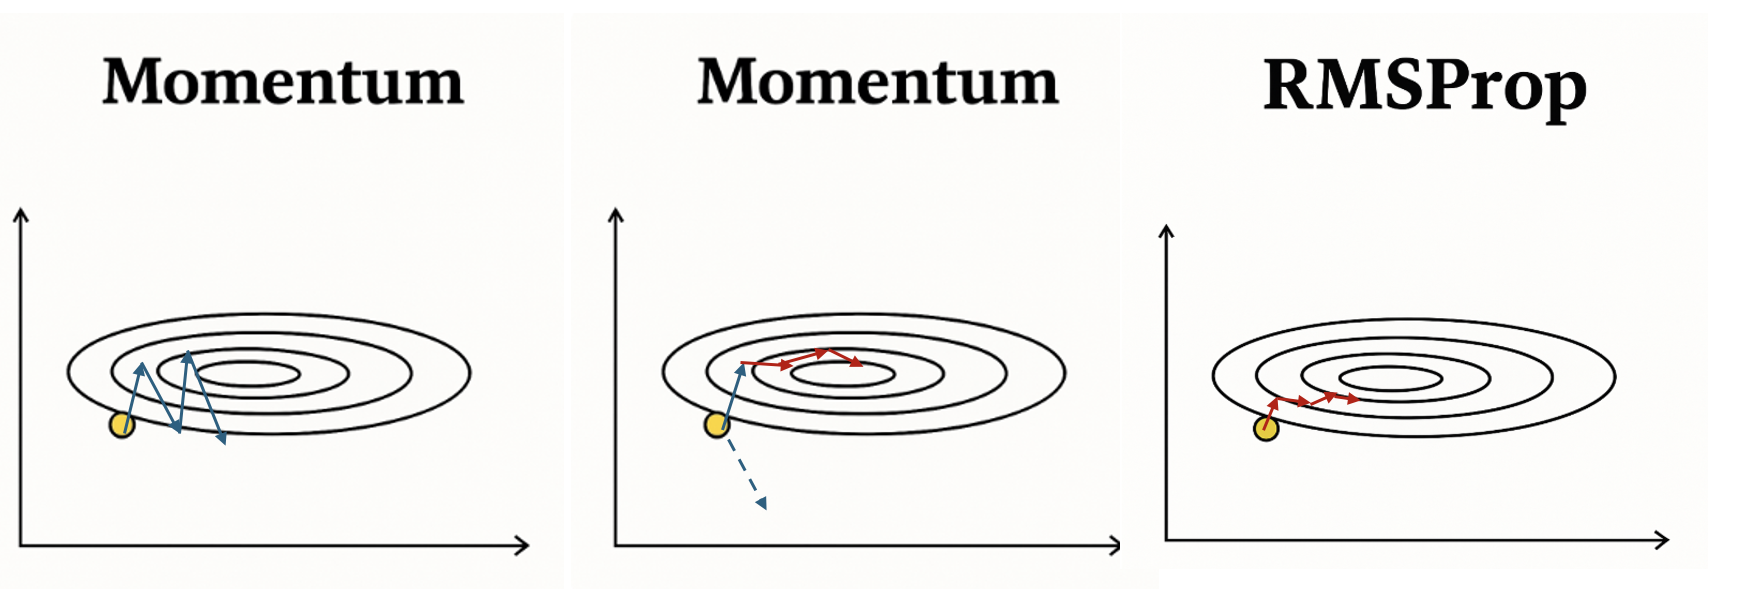
---

### 🔁 和直接用梯度的区别

#### 1. **普通SGD（无动量）**：

$$[
\theta_{t+1} = \theta_t - \alpha \cdot g_t
]$$

- 直接用当前梯度更新参数
- 容易震荡，学习率固定

---

#### 2. **加动量（如Momentum）**：

$$[
m_t = \beta \cdot m_{t-1} + (1 - \beta) \cdot g_t  
\quad \theta_{t+1} = \theta_t - \alpha \cdot m_t
]$$

- 用一阶动量代替直接梯度，方向更稳定

---

#### 3. **Adam（用一阶 + 二阶动量）**：

$$[
m_t = \beta_1 \cdot m_{t-1} + (1 - \beta_1) \cdot g_t  
\quad v_t = \beta_2 \cdot v_{t-1} + (1 - \beta_2) \cdot g_t^2  
\quad \theta_{t+1} = \theta_t - \alpha \cdot \frac{m_t}{\sqrt{v_t} + \epsilon}
]$$

- 一阶动量控制**方向**
- 二阶动量控制**步长**

---

简言之：  
**直接用梯度 = 方向太猛，容易翻车**  
**动量优化 = 稳又快，还能自动调速**

### ✅ 什么是混合精度训练？

![image.png](mixed-precision-diagram.svg)

### 混合精度训练的基本原理

1. **不同精度类型的结合**：
   - FP32（32位浮点数）：提供高精度但需要更多内存和计算资源
   - FP16（16位浮点数）：内存占用和计算速度更优，但精度较低
   - BF16（Brain浮点数）：在某些硬件上作为FP16的替代品，有更好的数值稳定性

2. **主要组成部分**：
   - 使用FP16进行前向和反向传播计算
   - 使用FP32存储主权重和优化器状态
   - 实施损失缩放(Loss Scaling)来防止梯度下溢

### 技术细节和实现

1. **损失缩放机制**：
   - 将损失值乘以一个因子（如2^n）
   - 这样反向传播中的梯度也会被相应放大
   - 防止小梯度在FP16表示中变为零
   - 更新权重前，梯度会被相应地缩小回原始比例

2. **典型的训练流程**：
   - FP32主权重复制到FP16
   - 使用FP16权重进行前向传播
   - 应用损失缩放
   - 使用FP16进行反向传播得到梯度
   - 将梯度转换回FP32并除以缩放因子
   - 使用FP32梯度更新FP32主权重

### 优势

1. **性能提升**：
   - 在支持FP16计算的硬件上可获得2-3倍的速度提升
   - 减少内存使用量，可训练更大的模型或使用更大的批量
   - 降低带宽瓶颈，因为数据传输量减半

2. **使用案例**：
   - 大型语言模型训练
   - 计算机视觉模型
   - 需要大批量或大模型的任何场景


### 到此，一次训练过程中，一个GPU中储存的参数量如下

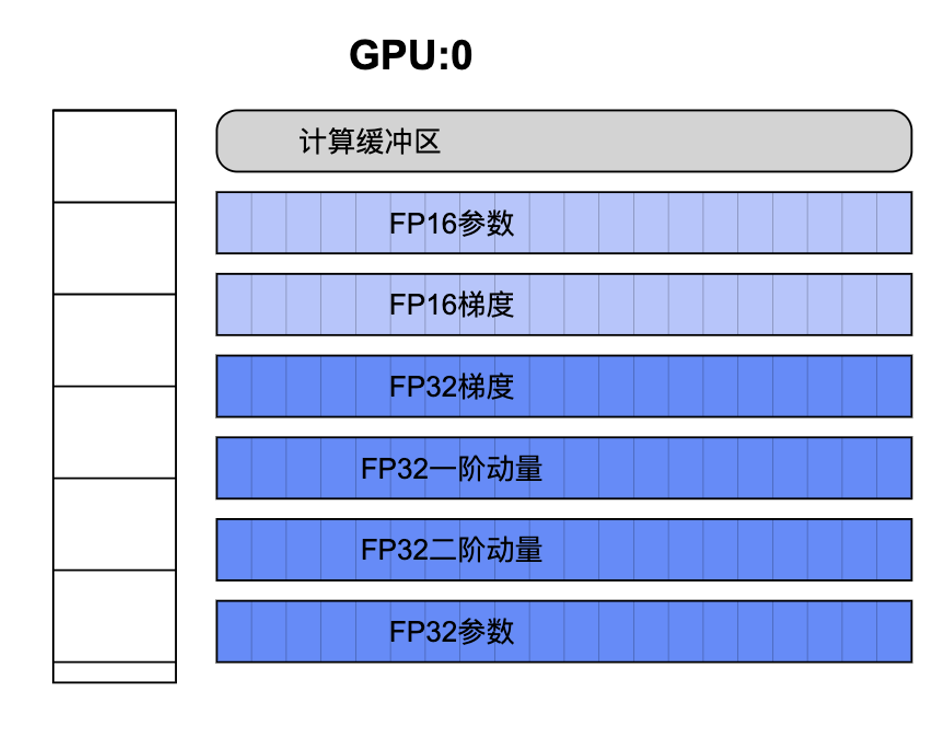

# 1. 数据并行

- 单机单卡的训练流程

![image.png](fine-tuning-pipeline-revised.svg)

## 1.1 DP&DDP
- 如果我们有多个GPU，是否可以**每个GPU一起去处理数据**

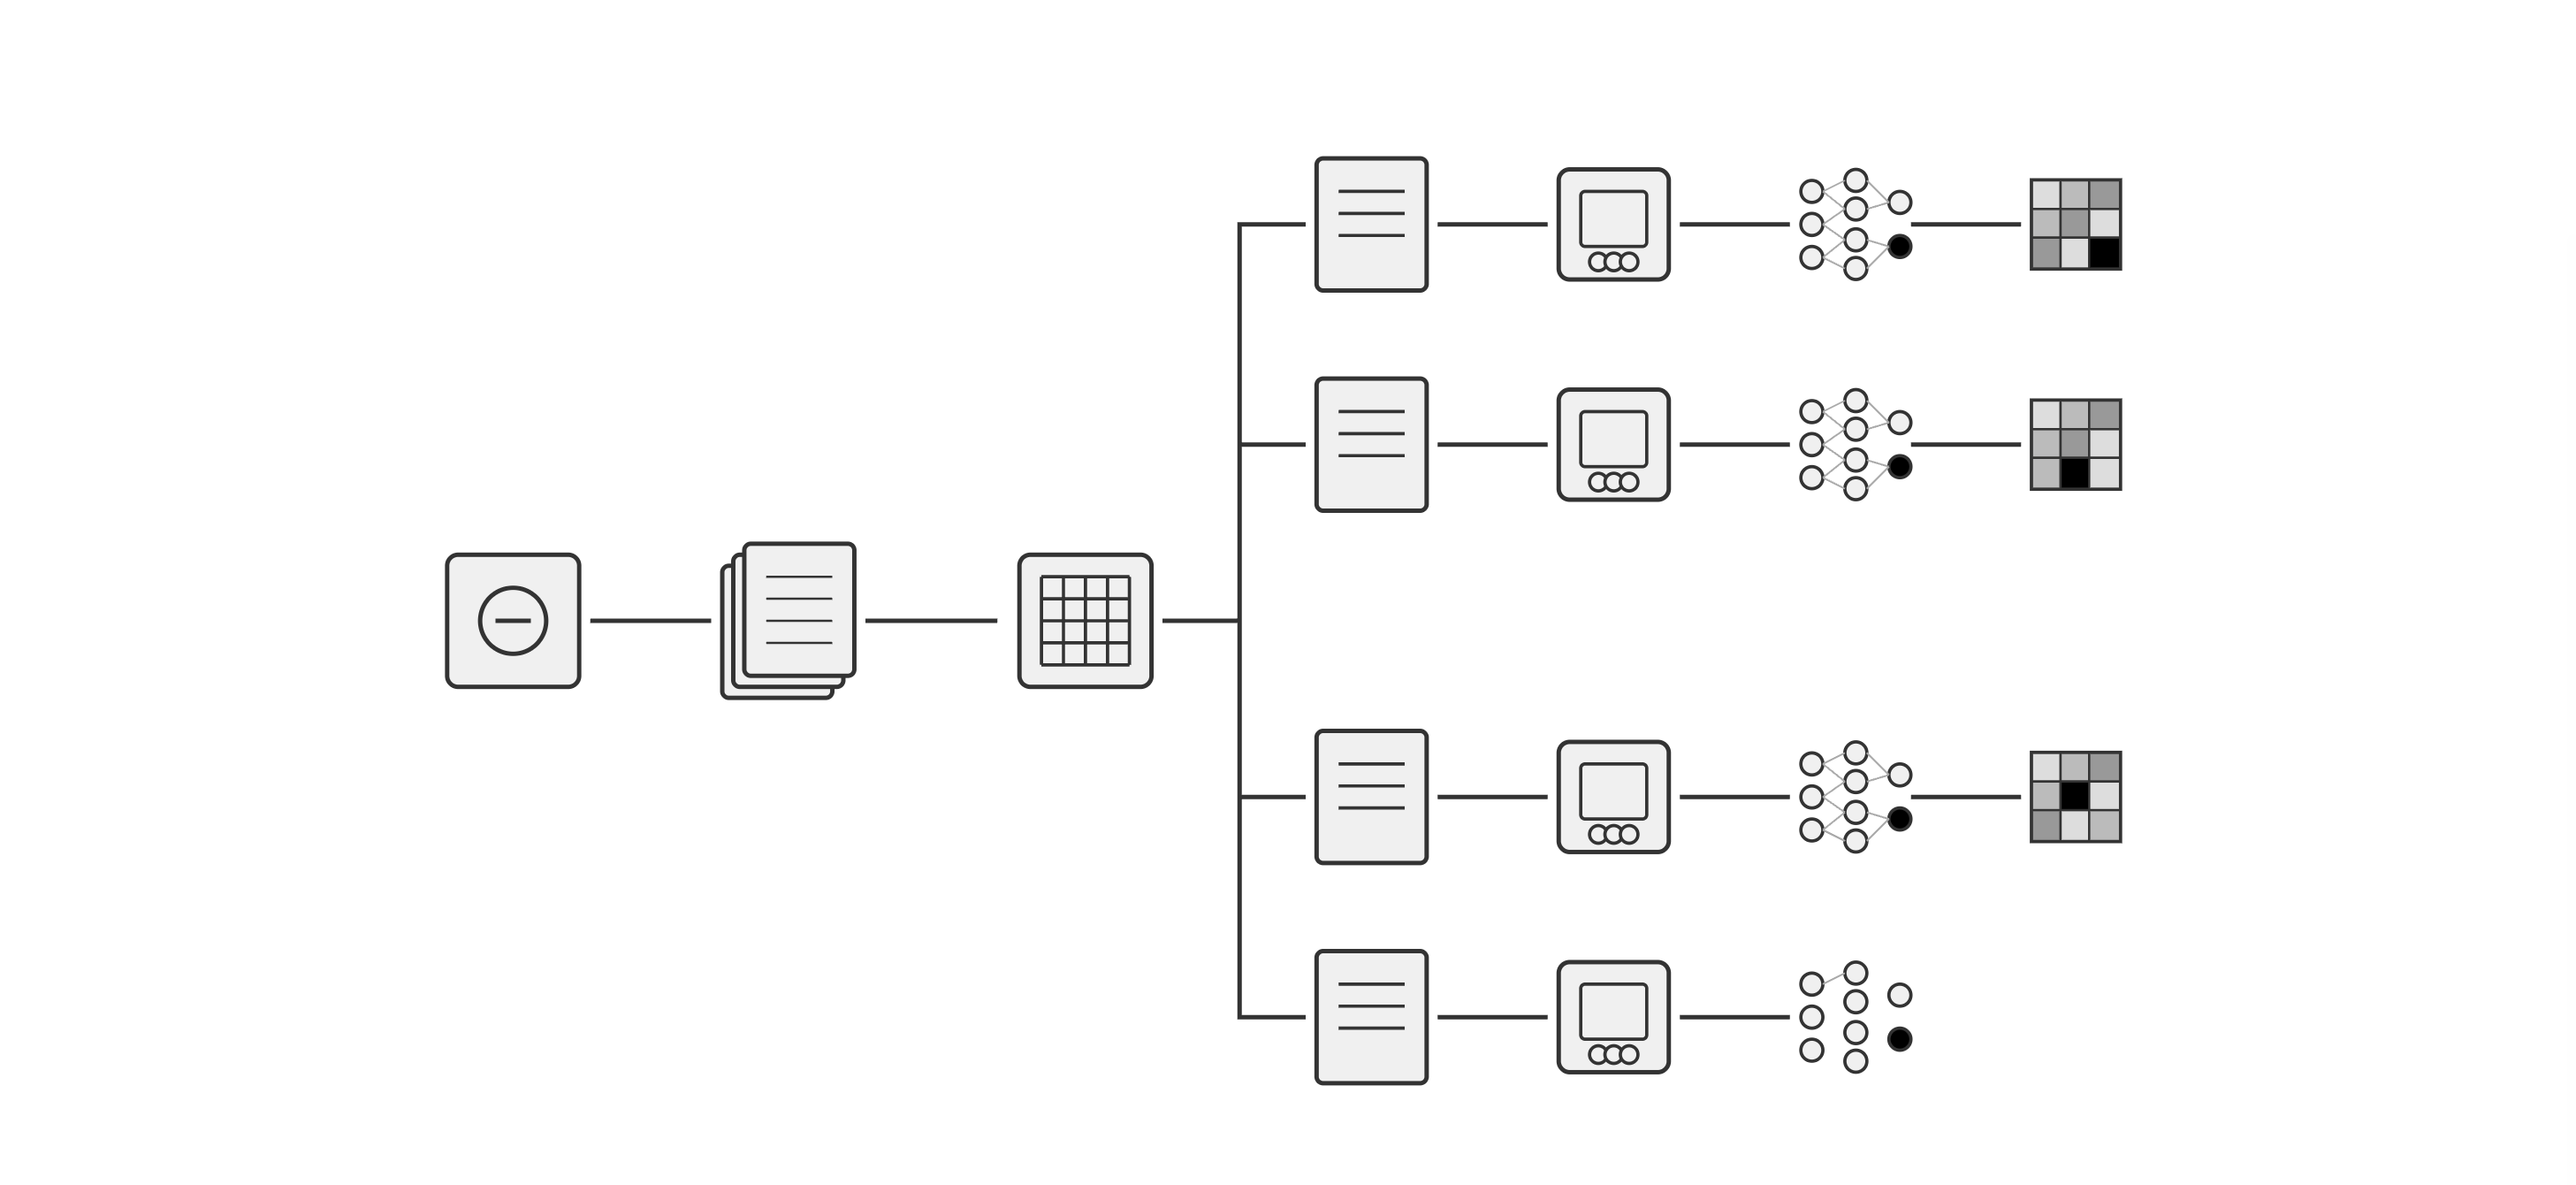

![image.png](gradient-sync-diagram.svg)

![image.png](ring-allreduce-steps.svg)



Ring-AllReduce与参数服务器模式的主要区别在于:

1. **带宽利用率**:
   - 参数服务器模式中，所有GPU同时与主GPU通信，导致主GPU的网络带宽成为瓶颈
   - Ring-AllReduce中，每个GPU只与两个相邻GPU通信，带宽分配更均匀

2. **并行度**:
   - 参数服务器模式是星型拓扑，通信必须经过中心节点
   - Ring-AllReduce是环形拓扑，通信可以并行进行

3. **负载均衡**:
   - 参数服务器模式中，主GPU承担了大量计算和通信负担
   - Ring-AllReduce中，所有GPU负载基本均衡

4. **可扩展性**:
   - 虽然两种模式的通信次数公式相似，但参数服务器模式在实践中随着GPU数量增加，主GPU的瓶颈效应会更明显
   - Ring-AllReduce在实践中表现出更好的可扩展性
  
#### 最核心的是通信时间几乎没有因为GPU数量而增加

Ring-AllReduce在带宽利用和并行通信方面有明显优势，特别是在大规模训练时。

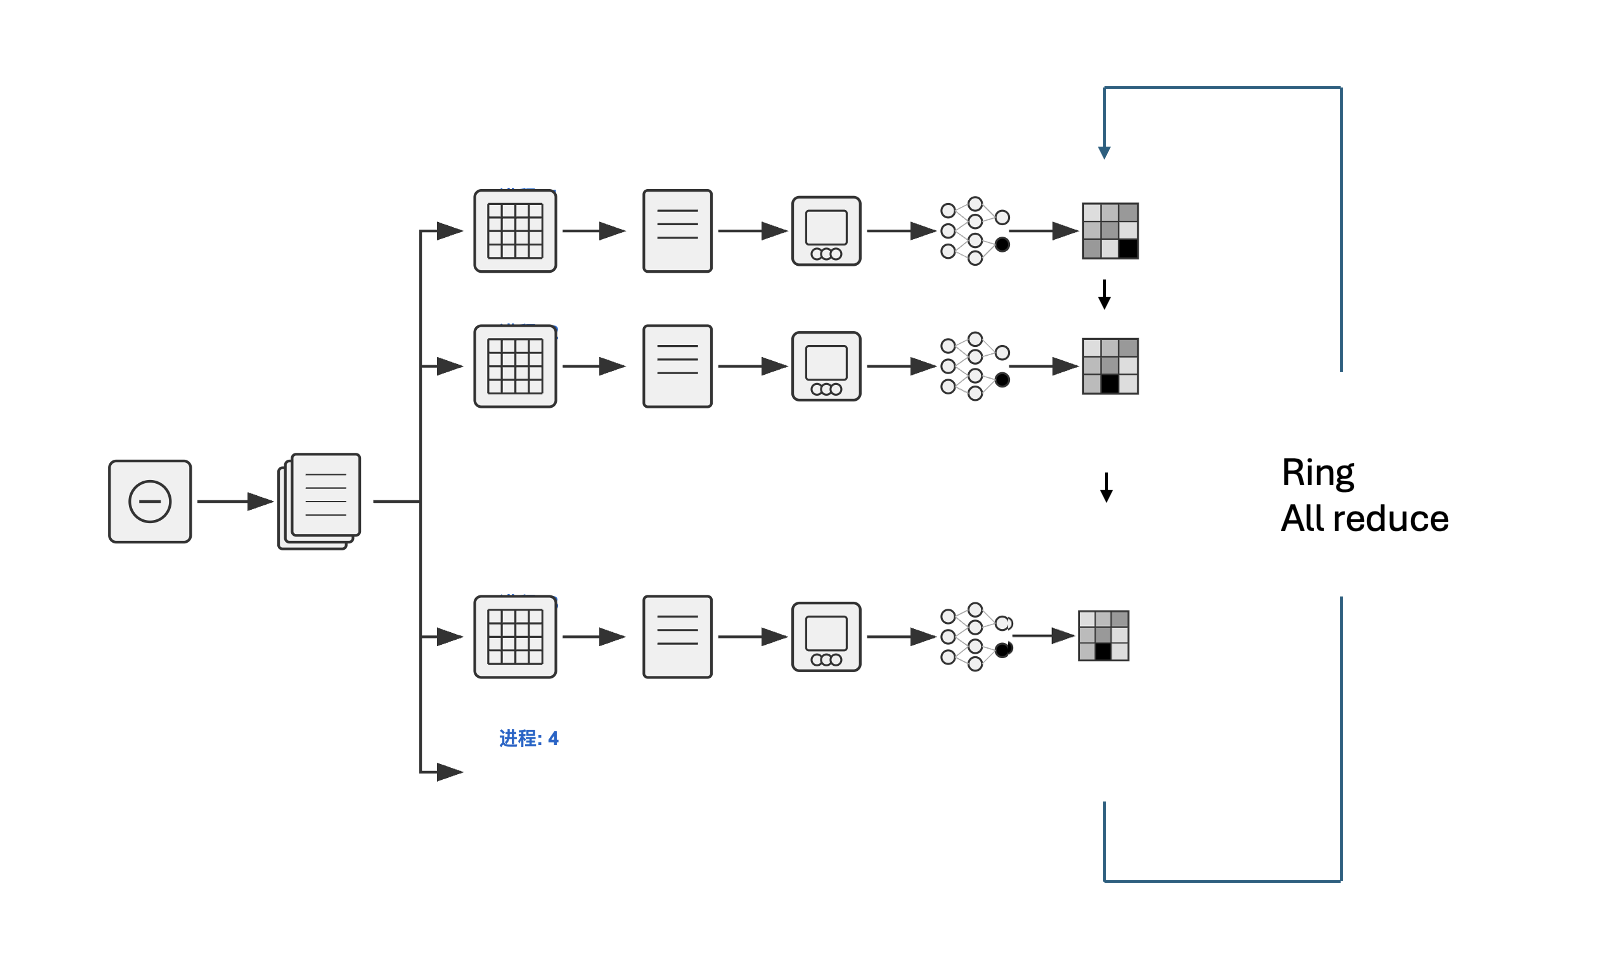

- 但是计算的时候并不是只要有了一部分参数就开始传递，而是等各自的桶装满之后开始传递

![image.png](barrel.png)

## DDP 的通信分析：

### 假设：
- 模型参数总量为：$\Psi$（大写 psi）
- GPU 数量为：$N$
- 每个 GPU 都有一份模型副本

#### 每轮通信（即一次梯度同步）中每个 GPU：

- **Scatter-Reduce 阶段通信量**：$\displaystyle (N-1) \cdot \frac{\Psi}{N} \approx \Psi$
- **AllGather 阶段通信量**：$\displaystyle (N-1) \cdot \frac{\Psi}{N} \approx \Psi$
- **总通信量** ≈ $2\Psi$

> ✅ **与 GPU 数量 $N$ 无关**，每个 GPU 总是传入/传出 $2\Psi$ 数据

---

### 再看 DP 的通信机制

DP 的通信与 DDP 不同，它是 **主进程集中式通信**：

- GPU0 是主 GPU，它负责：
  - 收集其他 GPU 的梯度（All Gather）
  - 执行参数更新
  - 将更新后的参数广播给其他 GPU（Broadcast）

### 假设还是 $N$ 张 GPU，其中 1 张为主（比如 GPU0）

#### 通信量分析：

- GPU0：
  - 接收：来自其他 $N-1$ 个 GPU 的梯度 → 共 $ (N-1)\Psi $
  - 发送：将更新后的参数广播给 $N-1$ 个 GPU → 共 $ (N-1)\Psi $
  - 总通信量：$2(N-1)\Psi$

- 非主 GPU（每张）：
  - 发送：$\Psi$（发给 GPU0）
  - 接收：$\Psi$（从 GPU0 收到更新参数）
  - 总通信量：$2\Psi$

---


## 1.2 DeepSpeed Zero-1

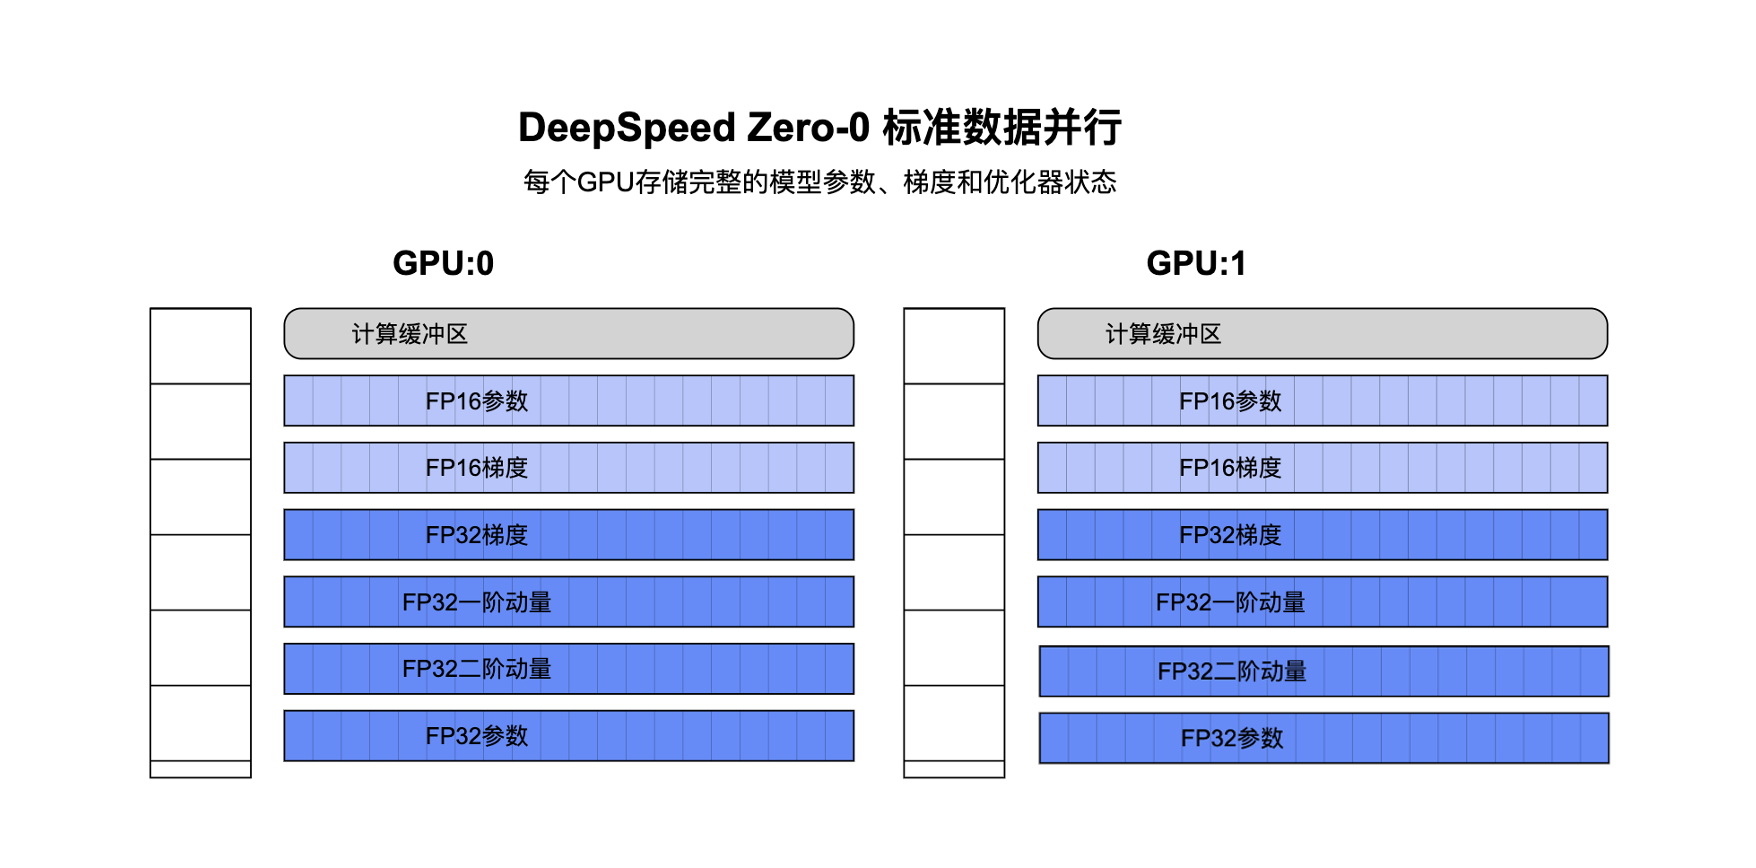

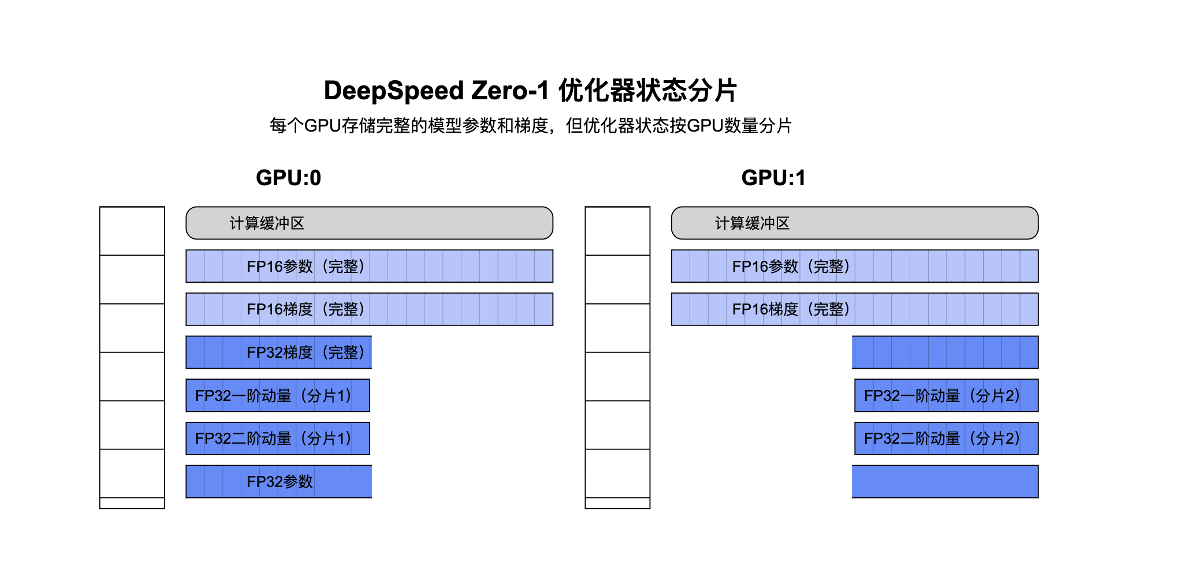

## ZeRO Stage 1：优化器状态（Optimizer States）的分片

### a. 背景问题

在传统的 **数据并行（Data Parallel）** 训练中，每张 GPU 都维护一份完整的模型参数、梯度和优化器状态。对于深度学习中常用的 Adam 等优化器，优化器状态通常会占用大量内存。例如：
- **参数（Parameters）**：模型本身需要的可训练参数；
- **梯度（Gradients）**：训练过程反向传播时计算得到的梯度；
- **优化器状态（Optimizer States）**：像 Adam 优化器中会维护两个额外张量（动量和二阶动量），每个大小都与参数本身相同。

当模型规模大时，这些部分的内存占用会变得非常可观，且在传统数据并行中会被所有 GPU 完整地各自存一份，显存需求呈线性倍增。

### b. Stage 1 的核心思想

**ZeRO Stage 1** 的核心是在多个 GPU 之间对优化器状态进行 **分片（Sharding）**，从而避免在每张 GPU 上都复制全部优化器状态。

- **传统方式（Data Parallel）**：  
  - 每张 GPU 都保存 \[参数 + 梯度 + 优化器状态\] 的完整拷贝。  
  - 比如 8 张 GPU 就会有 8 份完全相同的数据。

- **ZeRO Stage 1**：
  - **只分片优化器状态（Optimizer States）**，即将原本每张 GPU 都需要保存的整份状态分割成多个块（如 8 块），分给 8 张 GPU 各自保存其中的一块。
  - 而 **参数（Parameters）和梯度（Gradients）还是全量复制**，并没有被分片。
  - 当某张 GPU 需要更新自己对应的分片部分时，其他 GPU 不需要保留对应的优化器状态，从而减少重复存储。

在进行参数更新时，GPU 间会彼此通信，以获取更新所需要的那部分优化器状态。但由于计算过程中并不会同时访问所有参数的优化器状态（而是以一定的批次或分块进行），在总的训练过程中，内存使用量会减少显著。

### c. 实际效果

通过将优化器状态进行分片，**ZeRO Stage 1** 可以大幅度降低优化器状态带来的显存占用。对于一些使用大型优化器状态的情形（例如 Adam），优化器状态的大小可能是参数本身的 2~3 倍。将这部分分片后，单张 GPU 不再需要放完整的优化器状态，因此整体训练可以容纳更大的模型或使用更大的 batch size。

不过，需要注意的是：
- **ZeRO Stage 1 仍然在每张 GPU 上存有一整份模型参数和梯度**，这意味着如果模型非常大，参数本身的体量仍然可能让单卡显存不堪重负。
- 当模型更大、对内存需求更高时，会继续用 **ZeRO Stage 2**（再把梯度也分片）或 **ZeRO Stage 3**（进一步把参数也分片）的方式来更大幅度地减少显存占用。

### d. 训练流程示意

以下是一个基于 ZeRO Stage 1 的简化训练流程：

1. **初始化：**  
   - 将模型参数完整复制到每张 GPU。
   - 将优化器状态进行分割后分配到各张 GPU。假设有 8 张 GPU，就把优化器状态分成 8 份，每张 GPU 得到其中的一份。
   
2. **前向传播（Forward Pass）：**  
   - 每张 GPU 使用自己的全量参数计算前向传播，得到损失和部分中间结果。
   
3. **反向传播（Backward Pass）：**  
   - 每张 GPU 计算得到全量参数对应的梯度（与传统数据并行相同），此时梯度依然是复制在每张卡上的。
   
4. **参数更新（Optimizer Step）：**  
   - 在进行参数更新时，需要用到优化器状态。  
   - 由于状态被分片，不同 GPU 各有一部分优化器状态。  
   - DeepSpeed 框架在需要时，会从对应 GPU 上获取（或通过通信收集）更新所需的分片，然后进行参数更新。  
   - 更新完后，通过必要的通信，保证各卡上的参数保持一致。

### e. 优缺点总结

- **优点：**  
  1. 相比传统数据并行，显存占用大幅降低，能够让同样数量的 GPU 训练更大规模的模型。  
  2. 通信规模相对于全量复制会变小：只在需要访问对应分片时通信，减少了不必要的状态交换。

- **缺点：**  
  1. 参数和梯度仍然是全量复制。对于极大规模模型，Stage 1 的效果仍然不足以应对最苛刻的显存需求。  
  2. 需要在更新时进行通信调度，逻辑会更复杂，在一定程度上增加系统实现的复杂度。  
  3. 对于高速网络和 GPU 间通信的依赖更高，需要硬件基础设施较好，通信延迟大的场景中可能收益被削弱。

---

## DeepSpeed ZeRO-1 通讯量分析

- **参数量**：$$(\psi)$$
- **进程数**：$$(N)$$

对于每一个 GPU 进程：

1. **梯度收集（Reduce/All-Reduce）阶段**  
   - 传入/传出：$$(\displaystyle (N - 1)\,\frac{\psi}{N} \approx \psi)$$

2. **参数广播（Broadcast）阶段**  
   - 传入/传出：$$(\displaystyle (N - 1)\,\frac{\psi}{N} \approx \psi)$$

因此，对于每个 GPU 的 **总传入/传出** 约为：

$$[
2 \, \psi
]$$

与传统 **DDP (Distributed Data Parallel)** 的通讯量相同。


## Deepspeed Zero 1 节约显存分析

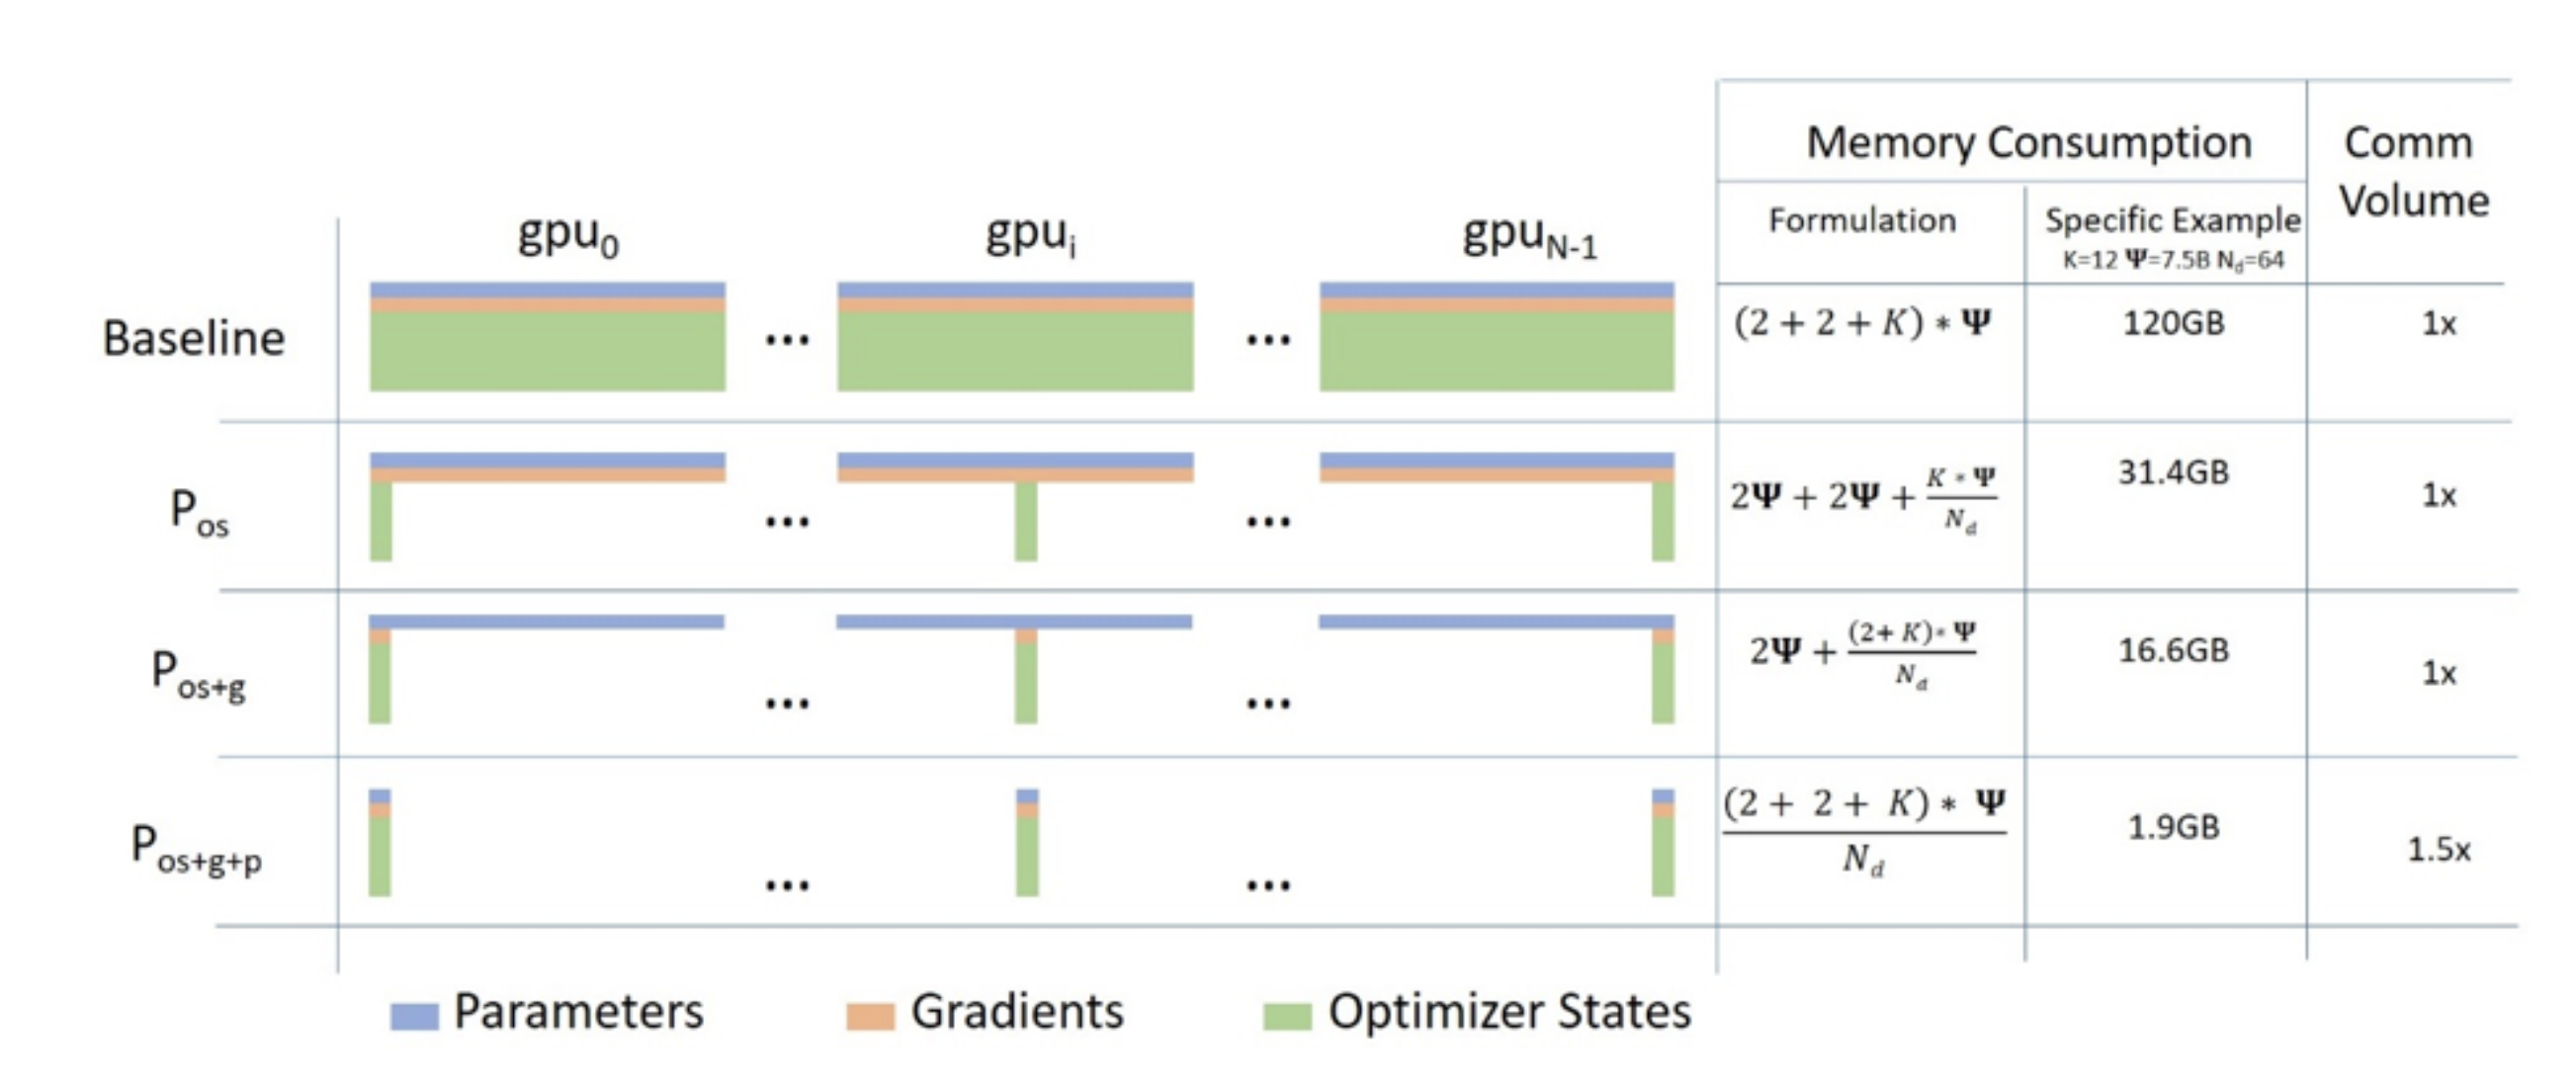

# 1.3 DeepSpeed Zero2

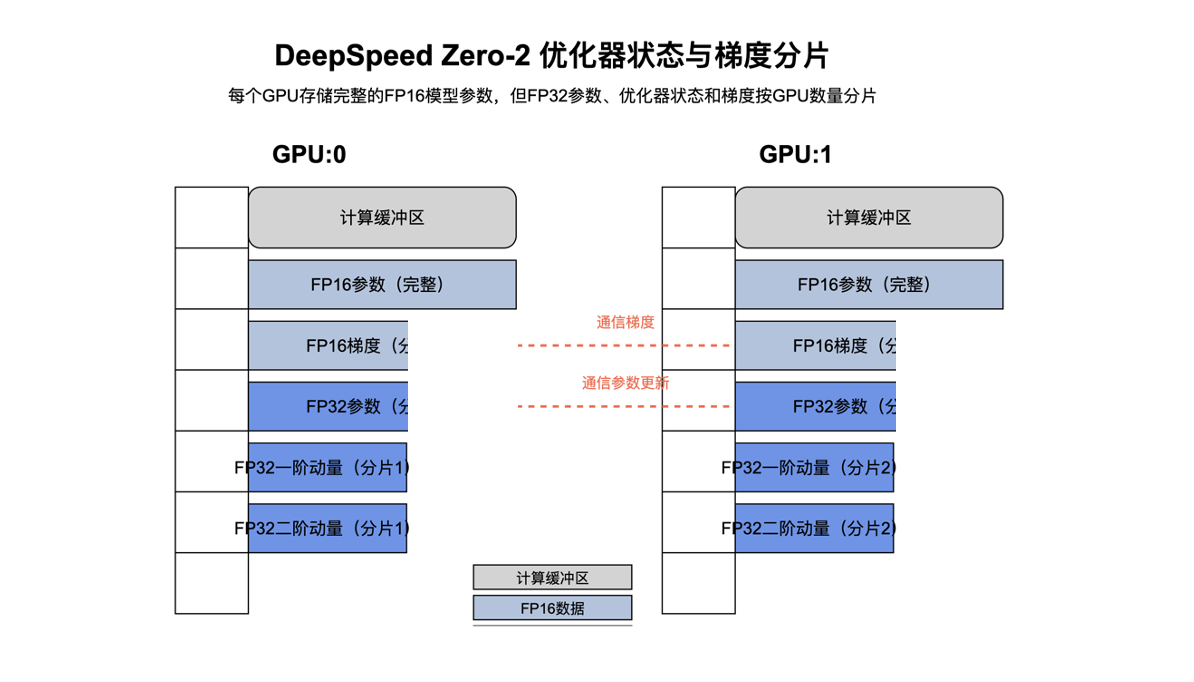

**DeepSpeed ZeRO**（Zero Redundancy Optimizer）是微软开源的分布式训练优化技术，通过对模型参数、梯度和优化器状态进行“分片（Sharding）”来降低大模型训练的显存开销。它分为多个阶段（Stage 1/2/3），每个阶段会在前一阶段的基础上进一步分摊或分片更多的数据结构，从而获得更高的显存节省。以下是对 **ZeRO Stage 2** 的详细解释。

---

### 1.3.1. 回顾 ZeRO Stage 1

- **Stage 1 只分片“优化器状态（Optimizer States）”**。即每张 GPU 仅保留自己负责更新的那部分优化器状态，而**模型参数（Parameters）和梯度（Gradients）** 依旧是**全量复制**在各张 GPU 上。  
- 这样已经解决了“优化器状态”重复占用显存的问题，但如果模型本身的参数量很大，仍然会因为参数和梯度在每张 GPU 上都存在完整拷贝而消耗大量显存。

### 1.3.3. Stage 2 的关键点：梯度分片

在 **Stage 2** 中，**除了继续对优化器状态进行分片**以外，还**对梯度（Gradients）**进行分片，从而进一步减少冗余的数据复制。

#### a 为什么要分片梯度？

在传统的数据并行（Data Parallel）里，梯度是每张 GPU 对全部模型参数做前向与反向传播后得到的。无论 GPU 有多少张，每张 GPU 都会计算并保留整套梯度。当模型规模增大，**梯度本身也占用了与参数相同量级的显存**。而在 ZeRO Stage 1 里，梯度依旧是被完整地复制在每张卡上。为了进一步降低显存开销，就需要将梯度也进行分片。

#### b 如何分片梯度？

1. 在反向传播过程中，各 GPU 会先计算与自己拥有的部分或全部参数相关的梯度。  
2. 通过通信（例如 All-Reduce 或者分块 Reduce），使得**每张 GPU 最终只保留自己负责的那一部分梯度**（分片），而不是保留整份梯度。  
3. 更新阶段（Optimizer Step）同样会涉及到通信，保证每张卡能够拿到需要用于参数更新的那部分梯度信息。


### 1.3.4 DeepSpeed ZeRO Stage 2 的工作流程

以一个简单的例子说明（假设有 4 张 GPU）：

1. **初始化**  
   - 每张 GPU 依旧保存完整的模型参数（与 Stage 1 保持一致）。  
   - 优化器状态已根据 Stage 1 的方法进行分片（即每张 GPU 保存模型某个分片的优化器状态）。  
   - **新增**：在后续训练过程中，梯度会被分片保留，而不是复制到每个 GPU。

2. **前向传播（Forward Pass）**  
   - 由于每张 GPU 都有完整模型参数，因此可以直接执行前向传播，得到损失和中间激活值（activations）。

3. **反向传播（Backward Pass）**  
   - 每张 GPU 都会对**本地的激活值**执行反向计算，并得到针对“全部模型参数”的局部梯度。  
   - 传统数据并行做法：此时会用 All-Reduce 将梯度同步到每张 GPU，上下文会有完整梯度。  
   - **ZeRO Stage 2 做法**：在训练过程中，通过一定的分块或分组调度，使得最后只有**需要更新本分片优化器状态**的 GPU 保留对应分片的梯度，其他分片会被释放或转移给相应的 GPU（可理解为先计算全量，再进行通信聚合并保留分片梯度，释放不需要的部分）。  
   - 得到的效果是：每张 GPU 最终只持有自己负责更新的那一部分梯度，而不是整个模型的梯度。

4. **更新参数（Optimizer Step）**  
   - 更新需要用到：  
     1. 参数对应的那块梯度；  
     2. 优化器状态对应的那块分片。  
   - 在 Stage 2 中，**参数依旧是完整保留**在每张 GPU 上，但优化器状态和梯度是分片的，所以需要确保 GPU 上已经准备好该分片的梯度和优化器状态。  
   - 更新完成后，可以通过必要的广播或同步操作，让所有 GPU 的参数副本保持一致（因为参数是全量复制的）。  
   - 相对于 Stage 1，这一步需要额外处理梯度分片的通信和同步逻辑。

5. **下一个小批次（Next Batch）**  
   - 重复上述过程，继续分片、聚合和释放梯度，更新相应的分片状态并同步到参数中。

---

### 1.3.5 Stage 2 的优势与挑战

#### 优势

1. **显存开销更小**  
   - 相比 Stage 1，梯度也被分片，单张 GPU 不再存储整套梯度，从而进一步减少显存消耗。  
   - 对超大模型来说，这能带来显著的内存节省，使得在同等硬件资源下可以训练更大规模的模型或使用更大的 batch size。

2. **适用大多数常见优化器**  
   - 和 Stage 1 一样，ZeRO Stage 2 支持常见的基于动量的优化器（如 Adam、AdamW 等），且能减轻大量重复维护优化器状态和梯度的内存开销。

3. **和数据并行的高兼容**  
   - DeepSpeed 在实现上与 PyTorch 的 DDP（DistributedDataParallel）等数据并行框架高度兼容，只是在内部通信和数据调度上做了较多优化。  
   - 用户可以以较小的修改量迁移到 ZeRO Stage 2。

#### 挑战

1. **通信量与带宽需求**  
   - 虽然分片可以减少本地显存使用，但在训练过程中需要更频繁或更复杂的通信。  
   - 如果硬件环境的带宽或网络延迟较高，通信会带来额外的开销，需要在实践中进行权衡。

2. **实现逻辑复杂度提高**  
   - 对梯度的分块、聚合、分发和释放需要更精细的调度，DeepSpeed 框架内部做了大量优化。  
   - 用户需要对 ZeRO 的原理和配置有一定了解，才能调整出最佳性能。

3. **对超大模型仍非终极方案**  
   - 虽然 Stage 2 已大幅节省了显存，但若模型规模进一步膨胀，参数在每张 GPU 上完整复制这一点仍会成为瓶颈。  
   - 这就引出了 **ZeRO Stage 3**，它会连**参数本身**也分片，从而达到更高的内存效率。




### 1.3.6 DeepSpeed ZeRO-2 通讯量分析

- **参数量**：$$(\psi)$$
- **进程数**：$$(N)$$

对于每一个 GPU 进程：

1. **梯度收集（Reduce/All-Reduce）阶段**  
   - 传入/传出：$$(\displaystyle (N - 1)\,\frac{\psi}{N} \approx \psi)$$

2. **参数广播（Broadcast）阶段**  
   - 传入/传出：$$(\displaystyle (N - 1)\,\frac{\psi}{N} \approx \psi)$$

因此，对于每个 GPU 的 **总传入/传出** 约为：

$$[
2 \, \psi
]$$

与传统 **DDP (Distributed Data Parallel)，Zero 1** 的通讯量相同。

### 1.3.7 DeepSpeed ZeRO-2 节约显存分析

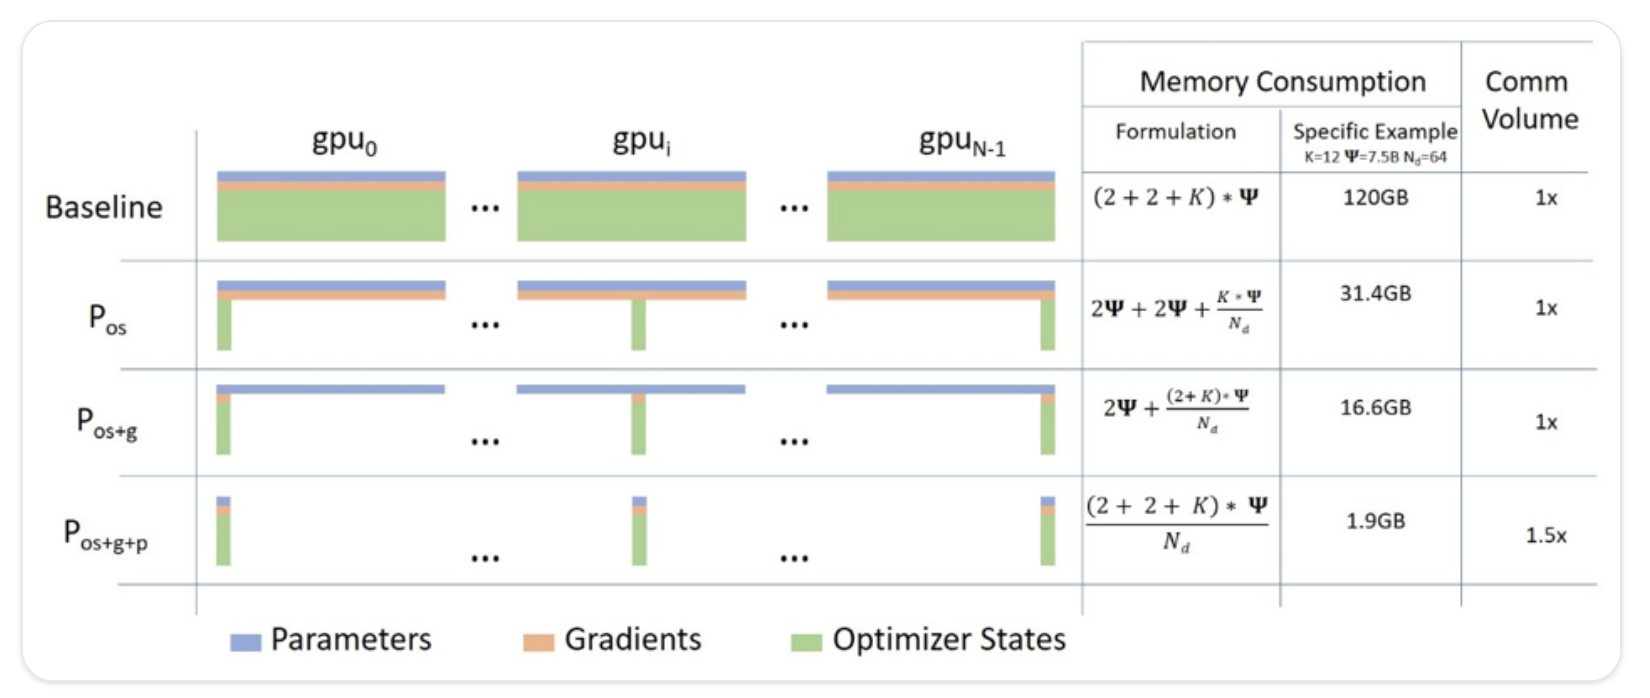

# 1.4 DeepSpeed Zero 3

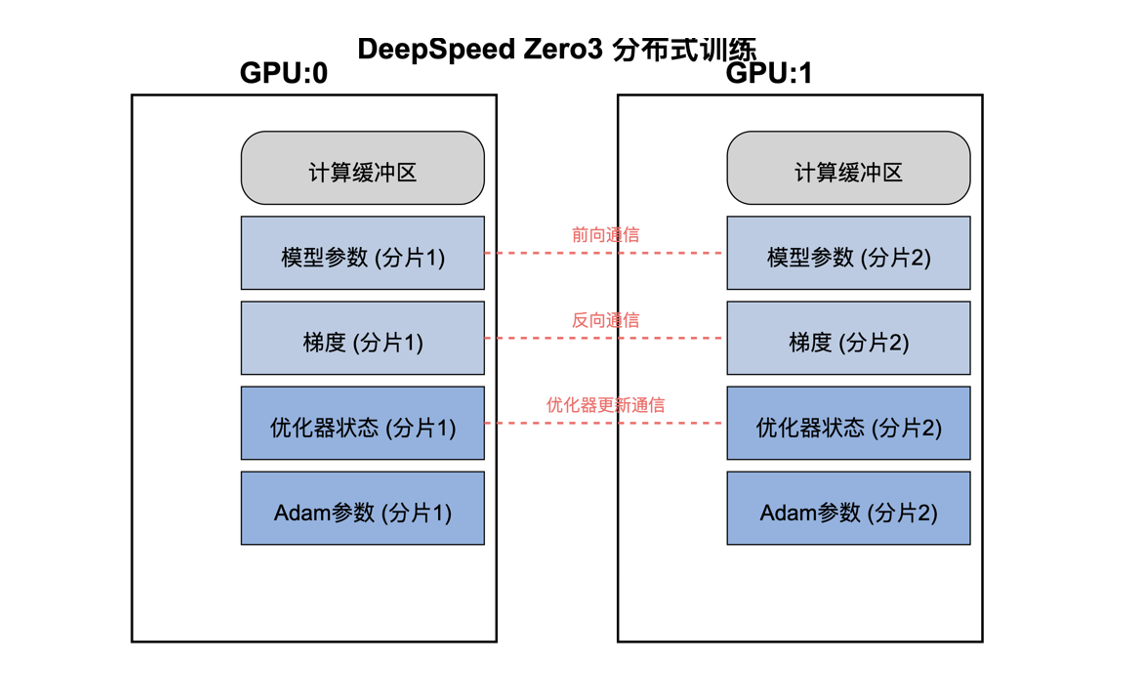

### Zero3 相比较1和2，反向传播时相同，区别在于正向传播时多了参数量的通信

---

**DeepSpeed Zero-3 通讯量分析**

参数量为ψ，进程数为N

对于每一个GPU进程：

- 梯度收集阶段传入/传出:  \((N - 1) \frac{ψ}{N} ≈ ψ\)  
- 参数广播阶段传入/传出:  \(2 * (N - 1) \frac{ψ}{N} ≈ 2ψ\)

总传入/传出：**3ψ**

是DDP传输量的**1.5倍**




# 2. 模型并行

## 2.1 张量并行

![image.png](tensor-parallel-diagram.svg)

### 张量并行（Tensor Parallelism）的原理与优势

张量并行是大模型训练和推理中的关键并行策略之一，主要解决单个GPU内存不足以存储完整模型参数的问题。

### 基本原理

1. **参数分割**：将神经网络层的权重矩阵沿特定维度切分成多个小块
2. **分布式计算**：每个GPU只负责存储和计算部分权重
3. **通信同步**：计算过程中需要GPU间通信以合并结果

### 实际应用方式

以Transformer模型的多头注意力机制为例：
- 可以将Q、K、V矩阵按照注意力头的数量进行划分
- 每个GPU负责计算几个注意力头
- 计算完成后通过All-reduce等集合通信操作合并结果

### 张量并行与其他并行方式的区别

- **数据并行**：复制整个模型，每个GPU处理不同的数据批次
- **张量并行**：分割模型参数，每个GPU存储部分模型
- **流水线并行**：按层划分模型，每个GPU负责连续的几层

### 优势

1. 突破单GPU内存限制，支持超大规模模型
2. 降低通信开销（相比某些其他并行方式）
3. 可与其他并行策略结合使用（混合并行）


## 2.2 流水线并行

![image.png](pipeline-parallelism.svg)

这张图解释了流水线并行的工作过程：

1. **纵向分配**：图中我们将一个神经网络模型分成4层，分别分配给4个不同的GPU。每个GPU专门负责处理模型的一个特定层。

2. **批次处理**：图中用不同颜色表示不同的数据批次（蓝色为批次1，红色为批次2，黄色为批次3，绿色为批次4）。

3. **时间维度**：从左到右表示时间的推移（T1到T6）。可以看到随着时间推移，数据批次如何在不同GPU之间传递。

4. **流水线效应**：
   - 在时间T1，批次1开始在GPU1上处理第1层
   - 到T2时，批次1移动到GPU2处理第2层，同时批次2进入GPU1开始处理
   - 到T3时，批次1移到GPU3，批次2移到GPU2，批次3进入GPU1
   - 到T4时，四个GPU都在工作，处理不同批次的不同层

5. **效率提升**：图中显示了当流水线完全填满后（从T4开始），所有GPU都在同时工作，没有空闲，从而提高了硬件利用率。

这种方式特别适合那些单个GPU无法容纳的大型模型，通过将模型垂直切分到多个设备上，同时让多个数据批次在这个"流水线"上流动，实现高效并行计算。

# 2.3 序列并行

![image.png](parallelism-comparison.svg)

## 序列并行与张量并行的区别

### 序列并行 (Sequence Parallelism)

序列并行主要针对输入序列进行切分，将一个长序列分成多个部分，由不同的计算设备处理：

1. **切分对象**：输入序列（如文本、token序列）
2. **工作方式**：每个GPU处理序列的不同部分（如GPU1处理前半部分tokens，GPU2处理后半部分tokens）
3. **适用场景**：特别适合处理超长序列输入的场景

### 张量并行 (Tensor Parallelism)

张量并行主要针对模型参数进行切分，将模型的权重矩阵分割到不同设备上：

1. **切分对象**：模型参数（权重矩阵）
2. **工作方式**：每个GPU存储并计算模型参数的不同部分
3. **适用场景**：模型参数量巨大，单个设备无法存储完整模型的场景

### 关键区别

1. **切分维度不同**：
   - 序列并行：在序列长度维度上切分
   - 张量并行：在模型参数维度上切分

2. **通信模式不同**：
   - 序列并行：在注意力机制计算时需要设备间交换序列信息
   - 张量并行：主要通过All-Reduce等集合通信操作合并计算结果

3. **解决的问题不同**：
   - 序列并行：主要解决序列长度受限的问题
   - 张量并行：主要解决模型参数量过大的问题

序列并行和张量并行常常结合使用，以充分利用硬件资源并扩展模型能力。在实际大模型部署中，通常会采用序列并行、张量并行和数据并行的混合策略，以达到最佳性能。

# 2.4 专家并行

![image.png](expert-parallelism.svg)

专家并行（Expert Parallelism）是大型语言模型训练和推理中的一种重要并行策略，特别适用于混合专家模型（Mixture of Experts，简称MoE）架构。

### 专家并行的基本概念

专家并行是指将模型中的"专家"网络分布在不同的计算设备上，每个设备负责处理一部分专家的计算。在MoE架构中，模型由多个"专家"子网络和一个路由器（Router或Gating Network）组成。

### 专家并行的工作原理

1. **路由机制**：输入先通过路由器，路由器决定将输入分配给哪些专家处理
2. **稀疏激活**：通常只有一部分专家被激活，比如对于每个输入只选择1-2个专家
3. **并行计算**：被选中的专家并行处理输入，各自独立计算
4. **结果聚合**：最后将各专家的输出根据路由权重合并为最终结果

### 专家并行的优势

1. **计算效率提升**：由于每次只激活部分专家，实际计算量远小于模型参数规模
2. **扩展性良好**：可以通过增加专家数量来扩大模型容量，而不会等比增加计算量
3. **专业化分工**：不同专家可以学习不同领域的知识，提高模型整体表现

### 专家并行的实现挑战

1. **负载均衡**：理想情况下，各专家被激活的频率应该均衡，避免部分专家过载
2. **通信开销**：专家分布在不同设备上会带来额外的通信成本
3. **路由算法优化**：路由器的设计直接影响模型性能和计算效率

### 代表性MoE模型

- **GShard**：Google提出的早期大规模MoE模型
- **Switch Transformer**：改进了路由机制的MoE模型
- **Mixtral 8x7B**：Mistral AI推出的混合专家模型，使用8个专家
- **Claude 3/GPT-4**：可能在内部架构中应用了MoE技术

专家并行是大模型向更大规模扩展的关键技术之一，它允许模型在不成比例增加推理计算量的情况下大幅增加参数量，从而提高模型能力。

## 手写Accelerate&Deepspeed

### DeepSpeed 与 Accelerate

#### 区别

**DeepSpeed** 是由 Microsoft 开发的一个深度学习优化库，旨在提高大规模模型训练的效率。它提供了多种优化技术，包括融合梯度训练、分布式训练、数据并行、模型并行和容器的内存映射等。

主要特点：

1. 分布式训练：支持数据并行、模型并行（包括管道并行和张量并行），使得训练大规模模型成为可能。
2. 优化器支持：提供优化算法，如 Zero（Zero Redundancy Optimizer）以减少显存占用，加速训练速度。
3. 混合精度训练：支持 FP16 和 BFLOAT16 混合精度训练，以减少计算和显存的占用。
4. 弹性训练：提供容错能力和断点恢复功能以实现训练重启。
5. 深度缓存：支持推理端，允许动态添加模块替代计算资源。

功能非常强大、丰富，但是配置起来比较复杂，需要一定的深度学习知识。

---

**Accelerate** 是由 Hugging Face 开发的一个库，旨在简化分布式训练的设置。它提供了一种简洁的方式来配置和管理多 GPU 和 TPU 训练，支持数据并行和处理并行。

主要特点：

1. 简化配置：提供统一的接口来处理多 GPU 和 TPU 环境的配置，简化了分布式训练的复杂性。
2. 支持多后端：可以与不同深度学习后端（如 PyTorch 和 TensorFlow）集成。
3. 集成 DeepSpeed：支持与 DeepSpeed 集成，利用 DeepSpeed 的高效功能训练模型。
4. 易于使用和快速启动：自动处理大多数配置问题，使用户能够专注于模型训练。

---
## Accelerate配置非常非常简单，而且可以集成DeepSpeed，而且不用担心数据和模型分别在哪儿的问题
避免**not match device**

### 配置环境

https://huggingface.co/docs/accelerate/quicktour

!pip install accelerate deepspeed transformers

accelerate config

### 配置文件
$Home/.cache/huggingface/accelerate/default_config.yaml

```json
compute_environment: LOCAL_MACHINE
debug: false
deepspeed_config:
  gradient_accumulation_steps: 1
  gradient_clipping: 1.0
distributed_type: MULTI_GPU
downcast_bf16: false
enable_cpu_affinity: false
machine_rank: 0
main_training_function: main
mixed_precision: "no"
num_machines: 1
num_processes: 2
rdzv_backend: static
same_network: false
tpu_use_cluster: false
tpu_use_sudo: false
use_cpu: false

```

### 🧩 **分布式训练** 的背景解释其中几个核心概念

#### 1. **world**
- **含义：** 分布式训练的“全世界”，也就是整个训练系统中参与的所有进程的集合。
- **关键参数：** `world_size`
- **举例：** 如果你用两台机器，每台2张GPU，那么 `world_size=4`，有4个训练进程。

---

#### 2. **processes**
- **含义：** 每一个训练进程，通常绑定一个 GPU 进行计算。
- **说明：** 分布式训练中，每个进程都执行相同的代码，只是处理不同的数据子集（data parallel）或模型子集（model parallel）。

---

#### 3. **gpu_id**
- **含义：** 当前进程所绑定的 GPU ID。
- **说明：** 如果你用 `torch.distributed.launch` 或 `accelerate launch` 启动，它会自动给每个进程分配 `local_rank`，也就是本机上的 `gpu_id`。

---

#### 4. **services**
- **含义：** 分布式训练中的**通信服务组件**或**控制服务**。
- **说明：** 这个词可能是指 backend（如 NCCL、Gloo）、或者指 master node 启动的 `Rendezvous` 服务，用于进程之间发现和同步。

---

### 它们之间的关系

```
         world
           |
     -----------------
     |       |       |
 process1 process2 process3 ...
     |        |
   gpu0     gpu1 ...
     |
 services（通信/调度）
```

---

### 🔑 总结

| 项目        | 含义 |
|-------------|------|
| `world`     | 所有参与训练的 GPU/进程的集合（world_size） |
| `processes` | 分布式训练的多个进程，分别负责训练一部分 |
| `gpu_id`    | 每个进程绑定的 GPU 号 |
| `services`  | 控制分布式训练协调/通信的后台服务（如 NCCL 后端，Rendezvous 等） |

---

想了解更具体的架构？比如 **DataParallel vs ModelParallel vs ZeRO** 的流程？我也可以画个图帮你总结。

### 可以直接用以下命令配置
python -c "import yaml; yaml.safe_dump({
    'compute_environment': 'LOCAL_MACHINE',
    'debug': False,
    'deepspeed_config': {
        'gradient_accumulation_steps': 1,
        'gradient_clipping': 1.0
    },
    'distributed_type': 'MULTI_GPU',
    'downcast_bf16': False,
    'enable_cpu_affinity': False,
    'machine_rank': 0,
    'main_training_function': 'main',
    'mixed_precision': 'no',
    'num_machines': 1,
    'num_processes': 2,
    'rdzv_backend': 'static',
    'same_network': False,
    'tpu_use_cluster': False,
    'tpu_use_sudo': False,
    'use_cpu': False
}, open('my_accelerate_config.yaml', 'w'))"


https://github.com/huggingface/accelerate/tree/main/examples/config_yaml_templates

## 接下来我们写一个数据并行的代码

一个batchsize64组数据，2台3090，完全一样的model，把64组数据分布到2个gpu上，放到gpu0上做模型更新，再同步

写一个train.py

!accelerate launch --config_file ./my_accelerate_config.yaml train.py

In [9]:
!accelerate launch --config_file my_accelerate_config.yaml train_trainer.py \
  --per_device_train_batch_size 32 \
  --num_train_epochs 3
  # 其他自定义参数3


[2025-04-06 12:00:07,517] [INFO] [real_accelerator.py:239:get_accelerator] Setting ds_accelerator to cuda (auto detect)
[2025-04-06 12:00:13,072] [INFO] [real_accelerator.py:239:get_accelerator] Setting ds_accelerator to cuda (auto detect)
[2025-04-06 12:00:13,239] [INFO] [real_accelerator.py:239:get_accelerator] Setting ds_accelerator to cuda (auto detect)
[2025-04-06 12:00:14,096] [INFO] [comm.py:658:init_distributed] cdb=None
[2025-04-06 12:00:14,096] [INFO] [comm.py:689:init_distributed] Initializing TorchBackend in DeepSpeed with backend nccl
[2025-04-06 12:00:14,223] [INFO] [comm.py:658:init_distributed] cdb=None
 99%|███████████████████████████████████████▍| 465/471 [00:02<00:00, 241.31it/s]Finished training & saved model to: trainer_output
{'train_runtime': 2.4965, 'train_samples_per_second': 12016.939, 'train_steps_per_second': 188.666, 'train_loss': 1.0251440870280986, 'epoch': 3.0}
100%|████████████████████████████████████████| 471/471 [00:02<00:00, 188.75it/s]
Finished trai

### 更详细地，deepspeed+accelerate按照以下的方式进行配置


#### 1. 写一个 `ds_config.json` 文件：
```json
{
  "train_batch_size": 32,
  "train_micro_batch_size_per_gpu": 16,
  "gradient_accumulation_steps": 1,
  "gradient_clipping": 1.0,
  "zero_optimization": {
    "stage": 2,
    "offload_optimizer": {
      "device": "none"
    },
    "offload_param": {
      "device": "none"
    }
  },
  "fp16": {
    "enabled": true
  }
}
```

#### 2. 修改你的 `accelerate_config.yaml`，把 `deepspeed_config` 改为指向这个 json：
```yaml
compute_environment: LOCAL_MACHINE
debug: false
deepspeed_config: ./ds_config.json
distributed_type: DEEPSPEED
downcast_bf16: false
enable_cpu_affinity: false
machine_rank: 0
main_training_function: main
mixed_precision: "fp16"
num_machines: 1
num_processes: 2
rdzv_backend: static
same_network: false
tpu_use_cluster: false
tpu_use_sudo: false
use_cpu: false
```

---

### 小结

| 配置 | 作用 |
|------|------|
| `accelerate_config.yaml` | 控制分布式策略、多卡数、是否用 DeepSpeed 等 |
| `ds_config.json`         | 控制 DeepSpeed 的核心逻辑，比如 ZeRO、优化器、精度等 |

---

## qwen2.5分布式训练（录播）